In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

df=pd.DataFrame({
    "student_Id": range(1,1001),
    "Year":(
        ["First"]*400
        
        +["Second"]*300
        +["Third"]*300
    )
})


# 2. Randomly select students from every group
sample = (
    df.groupby("Year", group_keys=False)
      .sample(frac=0.10, random_state=42)
)

# 3. Display results
print(sample)
print("\nStudents selected from each year:")
print(sample["Year"].value_counts())
print("\nTotal selected:", len(sample))

     student_Id   Year
209         210  First
280         281  First
33           34  First
210         211  First
93           94  First
..          ...    ...
922         923  Third
977         978  Third
852         853  Third
926         927  Third
983         984  Third

[100 rows x 2 columns]

Students selected from each year:
Year
First     40
Second    30
Third     30
Name: count, dtype: int64

Total selected: 100


REALTIME PROJECT


Original proportions:
Churn
No     0.7957
Yes    0.2043
Name: proportion, dtype: float64

Sample proportions:
Churn
No     0.7955
Yes    0.2045
Name: proportion, dtype: float64


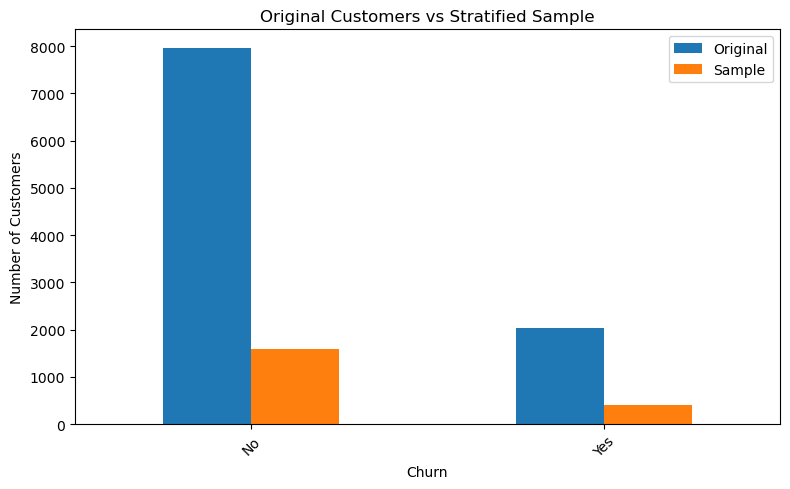

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

# 1. Create sample customer data
df = pd.DataFrame({
    "Customer_ID": range(1, 10001),
    "Churn": np.random.choice(
        ["Yes", "No"],
        size=10000,
        p=[0.20, 0.80]
    )
})

# 2. Stratified sampling: select 20% from each group
sample = (
    df.groupby("Churn", group_keys=False)
      .sample(frac=0.20, random_state=42)
)

# 3. Compare original and sampled proportions
print("Original proportions:")
print(df["Churn"].value_counts(normalize=True))

print("\nSample proportions:")
print(sample["Churn"].value_counts(normalize=True))

# 4. Visualize group counts
counts = pd.DataFrame({
    "Original": df["Churn"].value_counts(),
    "Sample": sample["Churn"].value_counts()
}).sort_index()

counts.plot(kind="bar", figsize=(8, 5))
plt.title("Original Customers vs Stratified Sample")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("realtime")
plt.show()